In [111]:
print("Hello world")

Hello world


## setup

In [112]:
import gzip
import json
from pathlib import Path
from urllib.parse import unquote

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..").resolve()
REFERENCE_GFF = ROOT / "E-coli_data/reference/GCF_000005845.2_ASM584v2_genomic.gff.gz"
PREDICTED_GFF = ROOT / "Structural_annotation/pyrodigal_results/ecoli_genes.gff"
OUT_DIR = ROOT / "validation/results/ecoli"
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"exact": "#2a78d6", "wrong_start": "#eb6834", "missed": "#1baf7a", "extra": "#eda100"}
LABELS = {"exact": "Exact", "wrong_start": "Wrong start", "missed": "Missed", "extra": "Extra"}
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
})

for path in (REFERENCE_GFF, PREDICTED_GFF):
    assert path.is_file(), path


## GFF reader

In [113]:
def parse_attributes(field):
    return dict(item.split("=", 1) for item in field.strip().strip(";").split(";") if "=" in item)


def read_cds(gff_path):
    """CDS features keyed by ID. CDS split over several lines (same ID) are merged into one gene."""
    opener = gzip.open if str(gff_path).endswith(".gz") else open
    genes = {}
    with opener(gff_path, "rt") as fh:
        for line in fh:
            if line.startswith("#") or not line.strip():
                continue
            contig, _, feature, start, end, _, strand, _, attributes = line.rstrip("\n").split("\t")
            if feature != "CDS":
                continue
            a = parse_attributes(attributes)
            gene = genes.setdefault(a["ID"], {
                "contig": contig, "strand": strand, "start": int(start), "end": int(end),
                "segments": 0, "pseudo": a.get("pseudo") == "true",
                "gene": a.get("gene", ""), "locus_tag": a.get("locus_tag", ""),
                "product": unquote(a.get("product", "")), "partial": a.get("partial", "00"),
                "uniprot": next((x.split(":", 1)[1] for x in a.get("Dbxref", "").split(",")
                                 if x.startswith("UniProtKB")), ""),
            })
            gene["start"] = min(gene["start"], int(start))
            gene["end"] = max(gene["end"], int(end))
            gene["segments"] += 1

    table = pd.DataFrame.from_dict(genes, orient="index")
    table.index.name = "id"
    table["length_bp"] = table["end"] - table["start"] + 1
    table["stop"] = table["end"].where(table["strand"] == "+", table["start"])
    table["first_base"] = table["start"].where(table["strand"] == "+", table["end"])
    return table


In [114]:
reference_all = read_cds(REFERENCE_GFF)
predicted = read_cds(PREDICTED_GFF)

is_split = reference_all["segments"] > 1
excluded = reference_all[reference_all["pseudo"] | is_split]
reference = reference_all.drop(excluded.index)

print(f"RefSeq CDS:            {len(reference_all)}")
print(f"  excluded pseudogenes: {excluded['pseudo'].sum()}")
print(f"  excluded split genes: {(~excluded['pseudo']).sum()}  {list(excluded.loc[~excluded['pseudo'], 'gene'])}")
print(f"Reference used:        {len(reference)}")
print(f"Predicted (Pyrodigal): {len(predicted)}")


RefSeq CDS:            4318
  excluded pseudogenes: 18
  excluded split genes: 3  ['dnaX', 'copA', 'prfB']
Reference used:        4297
Predicted (Pyrodigal): 4319


In [115]:
KEY = ["contig", "strand", "stop"]

shared_stop = reference[reference.duplicated(KEY, keep=False)].sort_values("stop")
reference_genes = reference.drop_duplicates(KEY)
print(f"{len(shared_stop)} RefSeq CDS share a stop codon with another CDS "
      f"(alternative start sites or overlapping genes); counted as {shared_stop.groupby(KEY).ngroups} genes")
print(f"Reference genes (unique stop codons): {len(reference_genes)}")

pairs = predicted.reset_index().merge(
    reference.reset_index(), on=KEY, how="outer", suffixes=("_pred", "_ref"), indicator=True,
)

# Positive shift = predicted start is downstream (protein too short); negative = too long
direction = pairs["strand"].map({"+": 1, "-": -1})
pairs["start_shift_bp"] = (pairs["first_base_pred"] - pairs["first_base_ref"]) * direction + 0  # "+ 0" turns -0 into 0

# Where several RefSeq CDS share a stop, keep the one whose start is closest to the prediction
found_rows = (pairs[pairs["_merge"] == "both"]
              .assign(abs_shift=lambda df: df["start_shift_bp"].abs())
              .sort_values("abs_shift")
              .drop_duplicates("id_pred"))
missed_rows = pairs[pairs["_merge"] == "right_only"].drop_duplicates(KEY)
extra_rows = pairs[pairs["_merge"] == "left_only"]

matched = pd.concat([found_rows, missed_rows, extra_rows], ignore_index=True)
matched["outcome"] = "extra"
matched.loc[matched["_merge"] == "right_only", "outcome"] = "missed"
matched.loc[(matched["_merge"] == "both") & (matched["start_shift_bp"] == 0), "outcome"] = "exact"
matched.loc[(matched["_merge"] == "both") & (matched["start_shift_bp"] != 0), "outcome"] = "wrong_start"

counts = matched["outcome"].value_counts().reindex(list(LABELS)).fillna(0).astype(int)
assert counts["exact"] + counts["wrong_start"] + counts["missed"] == len(reference_genes)
assert counts["exact"] + counts["wrong_start"] + counts["extra"] == len(predicted)
counts


19 RefSeq CDS share a stop codon with another CDS (alternative start sites or overlapping genes); counted as 9 genes
Reference genes (unique stop codons): 4287


outcome
exact          3889
wrong_start     229
missed          169
extra           201
Name: count, dtype: int64

In [116]:
found = counts["exact"] + counts["wrong_start"]
step1_metrics = {
    "refseq_cds_used": len(reference),
    "reference_genes": len(reference_genes),
    "predicted_genes": len(predicted),
    "excluded_pseudogenes": int(excluded["pseudo"].sum()),
    "excluded_split_genes": int((~excluded["pseudo"]).sum()),
    **{name: int(value) for name, value in counts.items()},
    "sensitivity_pct": round(float(100 * found / len(reference_genes)), 2),
    "precision_pct": round(float(100 * found / len(predicted)), 2),
    "exact_start_pct": round(float(100 * counts["exact"] / found), 2),
    "start_too_long": int((matched["start_shift_bp"] < 0).sum()),
    "start_too_short": int((matched["start_shift_bp"] > 0).sum()),
}

(OUT_DIR / "step1_genes_metrics.json").write_text(json.dumps(step1_metrics, indent=2))
pd.Series(step1_metrics, name="value").to_frame()


,value
refseq_cds_used,4297.00
reference_genes,4287.00
predicted_genes,4319.00
excluded_pseudogenes,18.00
excluded_split_genes,3.00
exact,3889.00
wrong_start,229.00
missed,169.00
extra,201.00
sensitivity_pct,96.06


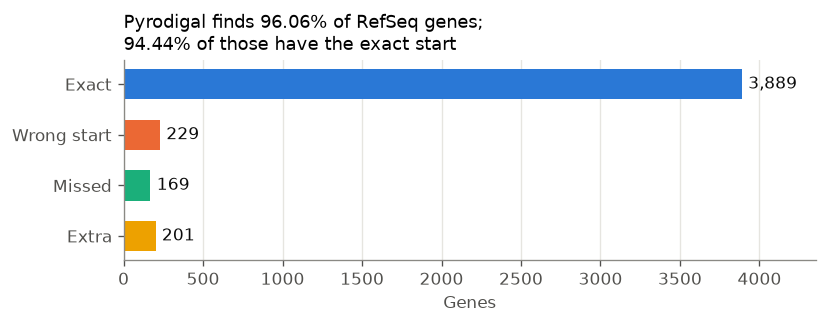

In [117]:
fig, ax = plt.subplots(figsize=(7, 2.8))
order = list(LABELS)[::-1]
ax.barh([LABELS[o] for o in order], [counts[o] for o in order],
        color=[COLORS[o] for o in order], height=0.6)
for y, o in enumerate(order):
    ax.text(counts[o] + 40, y, f"{counts[o]:,}", va="center", color="#0b0b0b")
ax.set_xlabel("Genes")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.max() * 1.12)
ax.set_title(f"Pyrodigal finds {step1_metrics['sensitivity_pct']}% of RefSeq genes;\n"
             f"{step1_metrics['exact_start_pct']}% of those have the exact start",
             loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step1_outcomes.png", dpi=200)
fig.savefig(OUT_DIR / "step1_outcomes.svg")
plt.show()


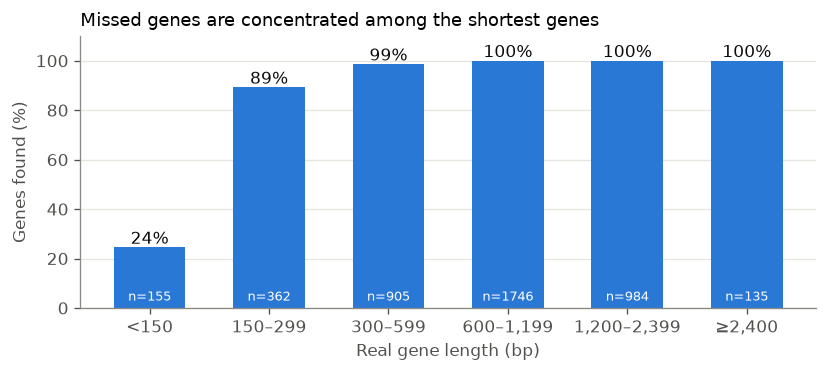

,genes,found,sensitivity_pct
length_bin,,,
<150,155,38,24.5
150–299,362,323,89.2
300–599,905,892,98.6
"600–1,199",1746,1746,100.0
"1,200–2,399",984,984,100.0
"≥2,400",135,135,100.0


In [118]:
bins = [0, 150, 300, 600, 1200, 2400, 100_000]
names = ["<150", "150–299", "300–599", "600–1,199", "1,200–2,399", "≥2,400"]

real = matched[matched["outcome"] != "extra"].copy()
real["length_bin"] = pd.cut(real["length_bp_ref"], bins=bins, labels=names, right=False)
by_length = real.groupby("length_bin", observed=False).agg(
    genes=("outcome", "size"),
    found=("outcome", lambda s: s.isin(["exact", "wrong_start"]).sum()),
)
by_length["sensitivity_pct"] = (100 * by_length["found"] / by_length["genes"]).round(1)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(by_length.index.astype(str), by_length["sensitivity_pct"], color=COLORS["exact"], width=0.6)
for x, (pct, n) in enumerate(zip(by_length["sensitivity_pct"], by_length["genes"])):
    ax.text(x, pct + 1.5, f"{pct:.0f}%", ha="center", color="#0b0b0b")
    ax.text(x, 3, f"n={n}", ha="center", color="white", fontsize=8)
ax.set_ylim(0, 110)
ax.set_xlabel("Real gene length (bp)")
ax.set_ylabel("Genes found (%)")
ax.grid(axis="x", visible=False)
ax.set_title("Missed genes are concentrated among the shortest genes", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step1_sensitivity_by_length.png", dpi=200)
fig.savefig(OUT_DIR / "step1_sensitivity_by_length.svg")
plt.show()
by_length


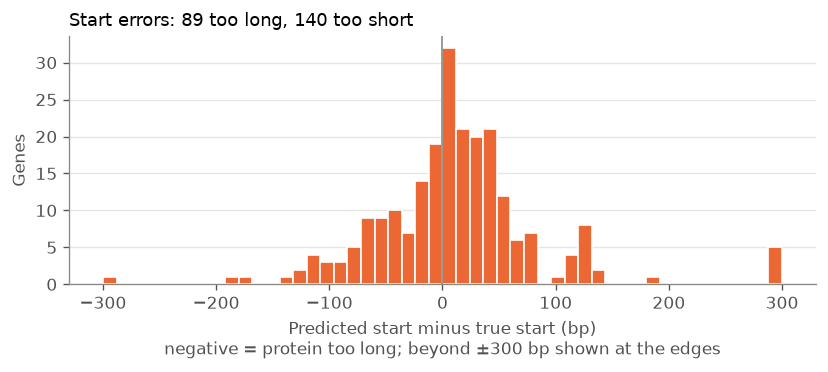

In [119]:
shifts = matched.loc[matched["outcome"] == "wrong_start", "start_shift_bp"]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(shifts.clip(-300, 300), bins=range(-300, 303, 12), color=COLORS["wrong_start"],
        edgecolor="white", linewidth=1)
ax.axvline(0, color="#8a8984", linewidth=1)
ax.set_xlabel("Predicted start minus true start (bp)\nnegative = protein too long; beyond ±300 bp shown at the edges")
ax.set_ylabel("Genes")
ax.grid(axis="x", visible=False)
ax.set_title(f"Start errors: {step1_metrics['start_too_long']} too long, "
             f"{step1_metrics['start_too_short']} too short", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step1_start_shifts.png", dpi=200)
fig.savefig(OUT_DIR / "step1_start_shifts.svg")
plt.show()


In [120]:
missed = (matched[matched["outcome"] == "missed"]
          [["id_ref", "gene_ref", "length_bp_ref", "product_ref"]]
          .sort_values("length_bp_ref"))
missed.head(15)


,id_ref,gene_ref,length_bp_ref,product_ref
4278,cds-YP_010051207.1,baxL,27.0,putative translational regulatory protein BaxL
4171,cds-YP_010051191.1,evgL,30.0,protein EvgL
4273,cds-YP_010051202.1,yhgP,30.0,protein YhgP
4218,cds-YP_010051177.1,ybgV,33.0,protein YbgV
4124,cds-YP_010283908.1,ykfO,33.0,protein YkfO
4286,cds-YP_010283920.1,ytiE,36.0,protein YtiE
4257,cds-YP_010051189.1,yoaM,36.0,protein YoaM
4272,cds-YP_010051201.1,yhgO,42.0,protein YhgO
4236,cds-YP_009518783.1,yddY,42.0,protein YddY
4174,cds-YP_010051192.1,pssL,42.0,protein PssL


## Step 2: Homology names (DIAMOND vs Swiss-Prot) compared with RefSeq

For every gene matched in step 1, compare the name our pipeline gave it with the official RefSeq name.
Both Swiss-Prot runs are evaluated: the full database, and the one without *Escherichia*/*Shigella* (simulating a new organism).

Each gene gets one category:

| Category | Rule |
|---|---|
| Correct: same gene | The Swiss-Prot match has the same gene symbol (`GN=`) as the RefSeq gene, ignoring case and copy numbers |
| Correct: similar name | Different symbol, but at least half of the meaningful words in the names are shared |
| Different name (review) | Both sides give a function, but the names don't match automatically; needs a human check |
| Function missed | RefSeq knows the function; we said uncharacterized or hypothetical |
| Function claimed, unknown | We gave a functional name; RefSeq says the function is unknown |
| Correctly unknown | Both say the function is unknown |

In [121]:
# Matched genes from step 1 (our protein <-> RefSeq gene). Rebuilt from step 1 if it has run, otherwise read from disk.
if "matched" in globals():
    gene_matches = matched[matched["outcome"].isin(["exact", "wrong_start"])].sort_values("first_base_pred")[[
        "id_pred", "id_ref", "gene_ref", "locus_tag_ref", "product_ref", "uniprot_ref",
        "outcome", "start_shift_bp",
    ]].rename(columns={
        "id_pred": "protein", "id_ref": "refseq_id", "gene_ref": "gene", "locus_tag_ref": "locus_tag",
        "product_ref": "refseq_product", "uniprot_ref": "uniprot",
    })
    gene_matches.to_csv(OUT_DIR / "gene_matches.tsv", sep="\t", index=False)
else:
    gene_matches = pd.read_csv(OUT_DIR / "gene_matches.tsv", sep="\t", keep_default_na=False)

print(f"{len(gene_matches)} matched genes; {(gene_matches['uniprot'] != '').sum()} have a UniProt ID")

4118 matched genes; 4106 have a UniProt ID


In [122]:
import re

HOMOLOGY_DIR = ROOT / "Structural_annotation/homology_results"
DATABASES = {"swissprot": "Full Swiss-Prot", "swissprot_no_ecoli": "Swiss-Prot without E. coli relatives"}
DIAMOND_FIELDS = ["qseqid", "sseqid", "pident", "length", "qlen", "slen",
                  "qcovhsp", "scovhsp", "evalue", "bitscore", "stitle"]

# RefSeq names that say nothing about function
UNKNOWN_FUNCTION = re.compile(
    r"^(uncharacterized|hypothetical|putative uncharacterized|upf0)"
    r"|^(putative )?protein y[a-z]{2}\w*$"
    r"|^(duf\d+ domain-containing|pf\d+ family) protein( y[a-z]{2}\w*)?$",
    re.IGNORECASE,
)
FILLER_WORDS = {"protein", "putative", "probable", "family", "the", "of", "and",
                "domain", "containing", "subunit", "like", "type", "predicted"}

CATEGORIES = {
    "correct_same_gene":    ("Correct: same gene",        "#2a78d6"),
    "correct_similar_name": ("Correct: similar name",     "#6da7ec"),
    "different_name":       ("Different name (review)",   "#eda100"),
    "under_annotated":      ("Function missed",           "#eb6834"),
    "over_annotated":       ("Function claimed, unknown", "#e87ba4"),
    "correctly_unknown":    ("Correctly unknown",         "#1baf7a"),
}


def name_words(name):
    """Meaningful lowercase words of a protein name."""
    return {w for w in re.sub(r"[^a-z0-9]+", " ", name.lower()).split()
            if w not in FILLER_WORDS and len(w) > 1}


def name_similarity(a, b):
    """Share of meaningful words two names have in common (0 to 1, Dice coefficient)."""
    a, b = name_words(a), name_words(b)
    return 2 * len(a & b) / (len(a) + len(b)) if a and b else 0.0


def gene_base(symbols):
    """Gene symbols lowercased, with trailing copy numbers removed (insH10 -> insh, ssb1 -> ssb)."""
    return symbols.str.lower().str.replace(r"\d+$", "", regex=True)

In [123]:
def evaluate_homology(database):
    """One row per matched gene: our name, the RefSeq name, and which category the pair falls into."""
    products = pd.read_csv(HOMOLOGY_DIR / f"ecoli_{database}_products.tsv", sep="\t", keep_default_na=False)
    hits = (pd.read_csv(HOMOLOGY_DIR / f"ecoli_{database}_hits.tsv", sep="\t", header=None,
                        names=DIAMOND_FIELDS, keep_default_na=False)
            .drop_duplicates(["qseqid", "sseqid"]))
    hits["match_gene"] = hits["stitle"].str.extract(r" GN=(\S+)")[0].fillna("")

    table = (gene_matches
             .merge(products, on="protein", how="left")
             .merge(hits[["qseqid", "sseqid", "match_gene"]],
                    left_on=["protein", "match_id"], right_on=["qseqid", "sseqid"], how="left"))
    table["match_gene"] = table["match_gene"].fillna("")

    truth_known = ~table["refseq_product"].str.contains(UNKNOWN_FUNCTION)
    we_named = table["status"] == "confident"
    same_gene = (gene_base(table["match_gene"]) == gene_base(table["gene"])) & (table["gene"] != "")
    table["name_similarity"] = [name_similarity(a, b) for a, b in zip(table["product"], table["refseq_product"])]

    table["category"] = "correctly_unknown"
    table.loc[~we_named & truth_known, "category"] = "under_annotated"
    table.loc[we_named & ~truth_known, "category"] = "over_annotated"
    both = we_named & truth_known
    table.loc[both, "category"] = "different_name"
    table.loc[both & (table["name_similarity"] >= 0.5), "category"] = "correct_similar_name"
    table.loc[both & same_gene, "category"] = "correct_same_gene"
    return table


homology = {db: evaluate_homology(db) for db in DATABASES}

/var/folders/6g/mc7s95_n393463z88d1hz47c0000gn/T/ipykernel_18114/700379788.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  truth_known = ~table["refseq_product"].str.contains(UNKNOWN_FUNCTION)
/var/folders/6g/mc7s95_n393463z88d1hz47c0000gn/T/ipykernel_18114/700379788.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  truth_known = ~table["refseq_product"].str.contains(UNKNOWN_FUNCTION)


### Metrics

- **named_pct**: share of genes given a functional name (status `confident`)
- **confirmed_correct_of_named_pct**: of genes we named *and* whose function RefSeq knows, the share automatically confirmed correct (a lower bound: some "different name" cases are also right)
- **known_functions_recovered_pct**: of all genes whose function RefSeq knows, the share we named correctly

In [124]:
def homology_metrics(table):
    counts = table["category"].value_counts().reindex(list(CATEGORIES)).fillna(0).astype(int)
    confirmed = counts["correct_same_gene"] + counts["correct_similar_name"]
    named_and_known = confirmed + counts["different_name"]
    known = named_and_known + counts["under_annotated"]
    return {
        "genes_evaluated": len(table),
        **{name: int(value) for name, value in counts.items()},
        "named_pct": round(float(100 * (table["status"] == "confident").mean()), 2),
        "confirmed_correct_of_named_pct": round(float(100 * confirmed / named_and_known), 2),
        "known_functions_recovered_pct": round(float(100 * confirmed / known), 2),
    }


step2_metrics = {db: homology_metrics(table) for db, table in homology.items()}
(OUT_DIR / "step2_homology_metrics.json").write_text(json.dumps(step2_metrics, indent=2))
pd.DataFrame(step2_metrics).rename(columns=DATABASES)

,Full Swiss-Prot,Swiss-Prot without E. coli relatives
genes_evaluated,4118.00,4118.00
correct_same_gene,3255.00,1838.00
correct_similar_name,80.00,222.00
different_name,80.00,318.00
under_annotated,351.00,1388.00
over_annotated,21.00,9.00
correctly_unknown,331.00,343.00
named_pct,83.44,57.97
confirmed_correct_of_named_pct,97.66,86.63
known_functions_recovered_pct,88.56,54.70


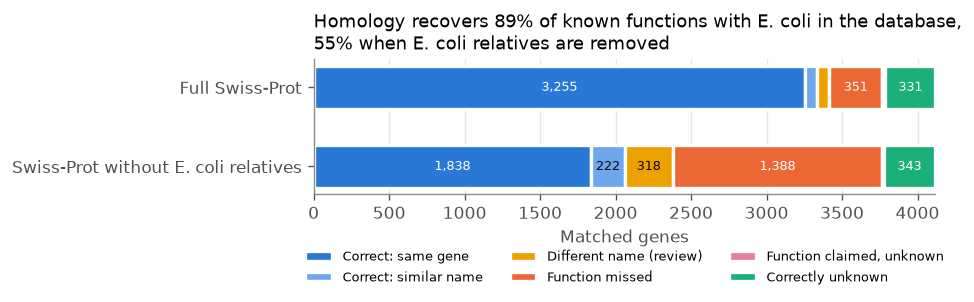

In [125]:
fig, ax = plt.subplots(figsize=(8, 3))
labels = [DATABASES[db] for db in DATABASES][::-1]
left = pd.Series(0, index=labels, dtype=float)
for key, (label, color) in CATEGORIES.items():
    values = pd.Series([step2_metrics[db][key] for db in DATABASES][::-1], index=labels)
    ax.barh(labels, values, left=left, color=color, label=label, height=0.55,
            edgecolor="white", linewidth=2)
    text_color = "#0b0b0b" if key in ("correct_similar_name", "different_name") else "white"
    for y, (value, start) in enumerate(zip(values, left)):
        if value >= 150:
            ax.text(start + value / 2, y, f"{value:,}", ha="center", va="center", color=text_color, fontsize=8)
    left += values
ax.set_xlabel("Matched genes")
ax.set_xlim(0, left.max())
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32), frameon=False, fontsize=8)
full, novel = (step2_metrics[db]["known_functions_recovered_pct"] for db in DATABASES)
ax.set_title(f"Homology recovers {full:.0f}% of known functions with E. coli in the database,\n"
             f"{novel:.0f}% when E. coli relatives are removed", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step2_homology_categories.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "step2_homology_categories.svg", bbox_inches="tight")
plt.show()

### Why were known functions missed?

For genes in the "Function missed" category, what did the homology step find?
`uncharacterized_match` = a good match, but its name was treated as uninformative; `weak_match` = only a distant match; `no_match` = nothing found.

In [126]:
missed_by_status = pd.DataFrame({
    DATABASES[db]: table.loc[table["category"] == "under_annotated", "status"].value_counts()
    for db, table in homology.items()
}).fillna(0).astype(int)
missed_by_status

,Full Swiss-Prot,Swiss-Prot without E. coli relatives
status,,
no_match,0,468
uncharacterized_match,334,95
weak_match,17,825


In [127]:
# Swiss-Prot names that start with "Uncharacterized" but still describe a function,
# e.g. "Uncharacterized HTH-type transcriptional regulator YjhI" (vs. plain "Uncharacterized protein YjhI")
partial = {}
for db, table in homology.items():
    rows = table[(table["category"] == "under_annotated")
                 & table["product"].str.match(r"(Putative )?[Uu]ncharacterized ")]
    description = (rows["product"]
                   .str.replace(r"^(Putative )?[Uu]ncharacterized ", "", regex=True)   # drop the prefix
                   .str.replace(r"\s+\S*\d\S*$|\s+Y[a-z]{2}[A-Z]?$", "", regex=True))  # drop a trailing gene/locus name
    partial[DATABASES[db]] = int((description.str.strip() != "protein").sum())
pd.Series(partial, name="missed genes whose Swiss-Prot name still hints at a function")

Full Swiss-Prot                         136
Swiss-Prot without E. coli relatives     36
Name: missed genes whose Swiss-Prot name still hints at a function, dtype: int64

### Examples and manual review

In [128]:
COLUMNS = ["protein", "gene", "refseq_product", "product", "match_gene", "status", "identity", "category"]
pd.set_option("display.max_colwidth", 80)

for category in ["different_name", "under_annotated", "over_annotated"]:
    for db, table in homology.items():
        rows = table.loc[table["category"] == category, COLUMNS]
        print(f"\n=== {DATABASES[db]}: {CATEGORIES[category][0]} ({len(rows)}) ===")
        display(rows.sample(min(8, len(rows)), random_state=1))


=== Full Swiss-Prot: Different name (review) (80) ===


,protein,gene,refseq_product,product,match_gene,status,identity,category
3179,NC_000913.3_3327,igaA,inner membrane protein involved in phosphorelay system,Putative membrane protein IgaA homolog,yrfF,confident,100,different_name
1413,NC_000913.3_1481,ydeS,putative fimbrial protein YdeS,Protein FimF,fimF,confident,45.1,different_name
1465,NC_000913.3_1536,ydfT,putative antitermination protein Q,Prophage antitermination protein Q homolog QuuQ,quuQ,confident,100,different_name
3551,NC_000913.3_3717,rffC,"dTDP-4-amino-4,6-dideoxy-D-galactose acyltransferase",dTDP-fucosamine acetyltransferase,wecD,confident,100,different_name
2399,NC_000913.3_2514,yphE,putative ABC transporter ATP-binding protein YphE,Ribose import ATP-binding protein RbsA 1,rbsA1,confident,41.7,different_name
2441,NC_000913.3_2558,yfiH,purine nucleoside phosphorylase YfiH,Peptidoglycan editing factor PgeF,pgeF,confident,100,different_name
2789,NC_000913.3_2925,yghO,putative DNA-binding transcriptional regulator YghO,Bacterial ceramide synthase,bcerS,confident,44.7,different_name
3974,NC_000913.3_4158,ridA,"enamine/imine deaminase, redox-regulated chaperone",2-iminobutanoate/2-iminopropanoate deaminase,yjgF,confident,100,different_name



=== Swiss-Prot without E. coli relatives: Different name (review) (318) ===


,protein,gene,refseq_product,product,match_gene,status,identity,category
1550,NC_000913.3_1628,nemA,N-ethylmaleimide reductase,Pentaerythritol tetranitrate reductase,onr,confident,87.7,different_name
1460,NC_000913.3_1530,rrrQ,putative lysozyme,SAR-endolysin,R,confident,89.8,different_name
1134,NC_000913.3_1184,ychQ,SirB family protein YchQ,Protein SirB2,sirB2,confident,73.4,different_name
1587,NC_000913.3_1665,ydiK,putative transporter YdiK,Putative transport protein bbp_117,bbp_117,confident,59.1,different_name
1594,NC_000913.3_1672,ydiO,putative acyl-CoA dehydrogenase YdiO,Crotonobetainyl-CoA reductase,caiA,confident,48.4,different_name
3058,NC_000913.3_3204,yhdY,putative ABC transporter membrane subunit YhdY,General L-amino acid transport system permease protein AapM,aapM,confident,49.1,different_name
2759,NC_000913.3_2895,yggR,Type II/IV secretion system family protein,Type IV pilus retraction ATPase PilT,pilT,confident,45.9,different_name
1222,NC_000913.3_1277,puuB,gamma-glutamylputrescine oxidase,Probable oxidoreductase OrdL,ordL,confident,41.1,different_name



=== Full Swiss-Prot: Function missed (351) ===


...

,protein,gene,refseq_product,product,match_gene,status,identity,category
803,NC_000913.3_844,amiD,N-acetylmuramoyl-L-alanine amidase D,hypothetical protein,ampD,weak_match,41.0,under_annotated
1310,NC_000913.3_1368,paaE,"phenylacetyl-CoA 1,2-epoxidase, reductase subunit",hypothetical protein,kshB,weak_match,35.1,under_annotated
4048,NC_000913.3_4246,yjiG,Gate family protein YjiG,hypothetical protein,,no_match,,under_annotated
2109,NC_000913.3_2216,yfaX,putative DNA-binding transcriptional regulator YfaX,hypothetical protein,bhcR,weak_match,31.8,under_annotated
1906,NC_000913.3_2000,wbbI,"beta-1,6-galactofuranosyltransferase WbbI",hypothetical protein,gtf3,weak_match,23.3,under_annotated
1667,NC_000913.3_1748,ydjF,putative DNA-binding transcriptional regulator YdjF,hypothetical protein,yulB,weak_match,36.9,under_annotated
2879,NC_000913.3_3018,ygjI,putative transporter YgjI,hypothetical protein,yjeM,weak_match,23.5,under_annotated
3362,NC_000913.3_3519,yiaV,putative membrane fusion protein YiaV,hypothetical protein,aaeA,weak_match,24.4,under_annotated



=== Full Swiss-Prot: Function claimed, unknown (21) ===


,protein,gene,refseq_product,product,match_gene,status,identity,category
2710,NC_000913.3_2845,ygfX,protein YgfX,Inner membrane protein YgfX,ygfX,confident,100,over_annotated
1337,NC_000913.3_1400,ydcJ,DUF1338 domain-containing protein YdcJ,2-oxoadipate dioxygenase/decarboxylase,ydcJ,confident,100,over_annotated
738,NC_000913.3_779,ybiJ,DUF1471 domain-containing protein YbiJ,Multiple stress resistance protein BhsA,bhsA,confident,41.9,over_annotated
3052,NC_000913.3_3195,yhdU,DUF2556 domain-containing protein YhdU,Inner membrane protein YhdU,yhdU,confident,100,over_annotated
3011,NC_000913.3_3154,yhcG,DUF1016 domain-containing protein YhcG,Putative nuclease YhcG,yhcG,confident,100,over_annotated
2458,NC_000913.3_2575,yfjD,UPF0053 family inner membrane protein YfjD,Inner membrane protein YfjD,yfjD,confident,100,over_annotated
2753,NC_000913.3_2889,yggI,protein YggI,Protein SprT,sprT,confident,100,over_annotated
852,NC_000913.3_893,ycaR,PF03966 family protein YcaR,Methyltransferase activator Trm112 homolog,ycaR,confident,100,over_annotated



=== Swiss-Prot without E. coli relatives: Function claimed, unknown (9) ===


,protein,gene,refseq_product,product,match_gene,status,identity,category
2753,NC_000913.3_2889,yggI,protein YggI,Protein SprT,sprT,confident,90.7,over_annotated
1167,NC_000913.3_1222,yciU,DUF440 domain-containing protein YciU,Putative double-stranded DNA mimic protein CKO_01325,CKO_01325,confident,93.6,over_annotated
2458,NC_000913.3_2575,yfjD,UPF0053 family inner membrane protein YfjD,Protein HI_0107,HI_0107,confident,60.9,over_annotated
2710,NC_000913.3_2845,ygfX,protein YgfX,Inner membrane protein YgfX,ygfX,confident,53.4,over_annotated
1016,NC_000913.3_1060,yceD,DUF177 domain-containing protein YceD,Large ribosomal RNA subunit accumulation protein YceD,yceD,confident,96.5,over_annotated
852,NC_000913.3_893,ycaR,PF03966 family protein YcaR,Methyltransferase activator Trm112 homolog,CKO_02153,confident,96.7,over_annotated
1337,NC_000913.3_1400,ydcJ,DUF1338 domain-containing protein YdcJ,2-oxoadipate dioxygenase/decarboxylase,hglS,confident,58.2,over_annotated
1241,NC_000913.3_1297,ycjX,DUF463 domain-containing protein YcjX,Ras-like GTPase HI_1637,HI_1637,confident,50.4,over_annotated


In [129]:
# 25 random "different name" cases per database, for checking by hand.
# Fill the same_function column with yes / partly / no. The file is never overwritten once it exists.
review = pd.concat([
    table.loc[table["category"] == "different_name", COLUMNS].sample(25, random_state=7).assign(database=db)
    for db, table in homology.items()
])
review["same_function"] = ""
review_file = OUT_DIR / "step2_manual_review.tsv"
if review_file.exists():
    print(f"{review_file.name} already exists; not overwriting your manual answers")
else:
    review.to_csv(review_file, sep="\t", index=False)
    print(f"Wrote {len(review)} rows to {review_file} for manual review")

step2_manual_review.tsv already exists; not overwriting your manual answers


In [130]:
# Run after filling in step2_manual_review.tsv
answers = pd.read_csv(review_file, sep="\t", keep_default_na=False)
filled = answers[answers["same_function"].str.strip() != ""]
if filled.empty:
    print("No answers yet: fill the same_function column in", review_file.name)
else:
    summary = (filled.groupby("database")["same_function"].value_counts(normalize=True)
               .mul(100).round(1).unstack(fill_value=0))
    display(summary)

No answers yet: fill the same_function column in step2_manual_review.tsv


## Step 3: Pfam domains (HMMER) compared with UniProt

For every matched gene that has a UniProt ID, compare the set of Pfam families we found with the set UniProt lists for that protein.

- **Family level**: the exact Pfam family must match.
- **Clan level**: related families (same Pfam clan) count as the same. This separates real mistakes from harmless near-duplicates such as ACT / ACT_7 / ACT_9 on the same region.
- **Overlap rule**: a simple fix we could add to the pipeline: when two domains of the same clan overlap on a protein, keep only the higher-scoring one. We measure what it would change.

Caveat: UniProt's Pfam annotations are produced with the same Pfam HMMs, so this measures **agreement with the reference**, not independent accuracy.

In [131]:
PFAM_HITS = ROOT / "Structural_annotation/pfam_results/ecoli_pfam_hits.tsv"
UNIPROT_PFAM = ROOT / "E-coli_data/reference/uniprot_pfam.tsv"
PFAM_CLANS = ROOT / "E-coli_data/reference/Pfam-A.clans.tsv.gz"

pfam_hits = pd.read_csv(PFAM_HITS, sep="\t", keep_default_na=False)
pfam_hits["family"] = pfam_hits["pfam_accession"].str.split(".").str[0]   # PF00696.34 -> PF00696

uniprot_pfam = pd.read_csv(UNIPROT_PFAM, sep="\t", keep_default_na=False)
uniprot_pfam_sets = {
    row["Entry"]: {p for p in row["Pfam"].strip(";").split(";") if p}
    for _, row in uniprot_pfam.iterrows()
}

clans = pd.read_csv(PFAM_CLANS, sep="\t", header=None, keep_default_na=False,
                    names=["family", "clan", "clan_name", "family_name", "description"])
clan_of = {f: (c or f) for f, c in zip(clans["family"], clans["clan"])}   # families without a clan stand alone
pfam_hits["clan"] = pfam_hits["family"].map(lambda f: clan_of.get(f, f))

print(f"{len(pfam_hits)} predicted domains on {pfam_hits['protein'].nunique()} proteins; "
      f"UniProt Pfam for {len(uniprot_pfam_sets)} proteins; {clans['clan'].replace('', pd.NA).nunique()} clans")

6601 predicted domains on 4119 proteins; UniProt Pfam for 4403 proteins; 891 clans


In [132]:
def resolve_clan_overlaps(domains):
    """Keep the best-scoring domain wherever two domains of the same clan overlap on a protein."""
    kept = []
    for _, d in domains.sort_values("domain_score", ascending=False).iterrows():
        clash = any(k["clan"] == d["clan"] and k["env_from"] <= d["env_to"] and d["env_from"] <= k["env_to"]
                    for k in kept)
        if not clash:
            kept.append(d)
    return {k["family"] for k in kept}


pfam_compare = gene_matches[gene_matches["uniprot"].isin(uniprot_pfam_sets.keys())][["protein", "gene", "uniprot", "outcome", "start_shift_bp"]].copy()
domains_by_protein = {p: d for p, d in pfam_hits.groupby("protein")}

pfam_compare["predicted"] = pfam_compare["protein"].map(lambda p: set(domains_by_protein[p]["family"]) if p in domains_by_protein else set())
pfam_compare["predicted_resolved"] = pfam_compare["protein"].map(lambda p: resolve_clan_overlaps(domains_by_protein[p]) if p in domains_by_protein else set())
pfam_compare["truth"] = pfam_compare["uniprot"].map(uniprot_pfam_sets)
to_clans = lambda families: {clan_of.get(f, f) for f in families}
print(f"Comparing {len(pfam_compare)} matched genes that have a UniProt entry")

Comparing 4106 matched genes that have a UniProt entry


In [133]:
def set_scores(predicted, truth):
    tp = sum(len(p & t) for p, t in zip(predicted, truth))
    fp = sum(len(p - t) for p, t in zip(predicted, truth))
    fn = sum(len(t - p) for p, t in zip(predicted, truth))
    return {"tp": tp, "fp": fp, "fn": fn,
            "precision_pct": round(100 * tp / (tp + fp), 2), "recall_pct": round(100 * tp / (tp + fn), 2)}


step3_metrics = {
    "family": set_scores(pfam_compare["predicted"], pfam_compare["truth"]),
    "family_after_overlap_rule": set_scores(pfam_compare["predicted_resolved"], pfam_compare["truth"]),
    "clan": set_scores(pfam_compare["predicted"].map(to_clans), pfam_compare["truth"].map(to_clans)),
}

# Why are predicted families "wrong"? Same clan as a true family (near-duplicate) or genuinely different?
false_families = [(f, t) for p, t in zip(pfam_compare["predicted"], pfam_compare["truth"]) for f in p - t]
same_clan = sum(clan_of.get(f, f) in to_clans(t) for f, t in false_families)
step3_metrics["false_positive_causes"] = {"same_clan_as_true_family": same_clan,
                                         "different_family": len(false_families) - same_clan}

# Per-protein agreement
def agreement(p, t):
    if not p and not t: return "no domains (both)"
    if p == t: return "identical"
    if p > t: return "extra families only"
    if p < t: return "missing families only"
    return "both extra and missing"

pfam_compare["agreement"] = [agreement(p, t) for p, t in zip(pfam_compare["predicted"], pfam_compare["truth"])]
step3_metrics["per_protein"] = pfam_compare["agreement"].value_counts().to_dict()

(OUT_DIR / "step3_pfam_metrics.json").write_text(json.dumps(step3_metrics, indent=2))
pd.DataFrame({k: v for k, v in step3_metrics.items() if k in ("family", "family_after_overlap_rule", "clan")})

,family,family_after_overlap_rule,clan
tp,6155.00,6155.00,5832.00
fp,19.00,19.00,14.00
fn,19.00,19.00,5.00
precision_pct,99.69,99.69,99.76
recall_pct,99.69,99.69,99.91


In [134]:
pd.Series(step3_metrics["false_positive_causes"], name="predicted families not in UniProt").to_frame().join(
    pd.Series(step3_metrics["per_protein"], name="proteins"), how="outer")

,predicted families not in UniProt,proteins
both extra and missing,NaN,6.0
different_family,14.0,NaN
extra families only,NaN,12.0
identical,NaN,3973.0
missing families only,NaN,13.0
no domains (both),NaN,102.0
same_clan_as_true_family,5.0,NaN


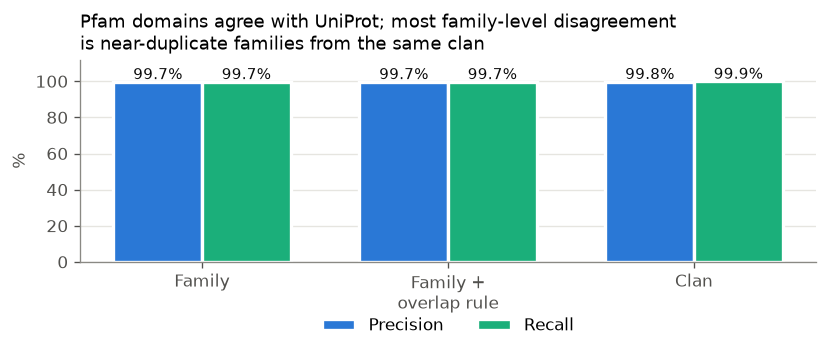

In [135]:
levels = {"family": "Family", "family_after_overlap_rule": "Family +\noverlap rule", "clan": "Clan"}
fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.36
for offset, (measure, label, color) in zip((-width / 2, width / 2),
                                           [("precision_pct", "Precision", "#2a78d6"), ("recall_pct", "Recall", "#1baf7a")]):
    values = [step3_metrics[level][measure] for level in levels]
    bars = ax.bar([i + offset for i in range(len(levels))], values, width=width, color=color, label=label,
                  edgecolor="white", linewidth=2)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.1f}%", ha="center", color="#0b0b0b", fontsize=9)
ax.set_xticks(range(len(levels)))
ax.set_xticklabels(levels.values())
ax.set_ylim(0, 112)
ax.set_ylabel("%")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_title("Pfam domains agree with UniProt; most family-level disagreement\nis near-duplicate families from the same clan",
             loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step3_pfam_agreement.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "step3_pfam_agreement.svg", bbox_inches="tight")
plt.show()

### Do wrong gene starts (step 1) cost domains?

A gene predicted with a start that is too late gives a protein that is too short, which can lose its first domain.

In [136]:
pfam_compare["start"] = pd.cut(pfam_compare["start_shift_bp"].fillna(0), [-1e9, -0.5, 0.5, 1e9],
                               labels=["too long", "exact", "too short"])
start_effect = pd.DataFrame({
    group: set_scores(rows["predicted"], rows["truth"]) | {"genes": len(rows)}
    for group, rows in pfam_compare.groupby("start", observed=True)
}).T[["genes", "recall_pct", "precision_pct"]]
start_effect

,genes,recall_pct,precision_pct
too long,88.0,100.00,98.54
exact,3879.0,99.78,99.78
too short,139.0,97.30,98.18


In [137]:
pd.set_option("display.max_colwidth", 80)
examples = pfam_compare[pfam_compare["agreement"].isin(["missing families only", "both extra and missing"])].copy()
examples["missing"] = [", ".join(sorted(t - p)) for p, t in zip(examples["predicted"], examples["truth"])]
examples["extra"] = [", ".join(sorted(p - t)) for p, t in zip(examples["predicted"], examples["truth"])]
examples[["protein", "gene", "outcome", "start_shift_bp", "missing", "extra"]].sample(min(10, len(examples)), random_state=1)

,protein,gene,outcome,start_shift_bp,missing,extra
151,NC_000913.3_1356,ldhA,exact,0.0,PF00389,
1059,NC_000913.3_3563,waaB,exact,0.0,PF13439,
123,NC_000913.3_1799,rlmA,exact,0.0,PF13847,PF13649
3575,NC_000913.3_2817,xdhC,exact,0.0,PF00111,
4117,NC_000913.3_1347,stfR,wrong_start,1365.0,PF08400,"PF03406, PF12604"
4114,NC_000913.3_3490,insK,wrong_start,486.0,PF13276,
4116,NC_000913.3_1451,fdnG,wrong_start,636.0,PF04879,
4115,NC_000913.3_3814,fdoG,wrong_start,636.0,PF04879,
1666,NC_000913.3_2290,pdxB,exact,0.0,PF00389,
3992,NC_000913.3_400,secD,wrong_start,33.0,PF02355,PF03176


## Step 4: GO terms (pfam2go) compared with the GO Consortium annotation of E. coli MG1655

Ground truth: `18.E_coli_MG1655.goa` (UniProt-GOA). Two versions of the truth are used, because many GO annotations are computer-inferred (`IEA`) from the same InterPro2GO mapping our `pfam2go` file comes from:

- **Experimental**: evidence codes EXP, IDA, IPI, IMP, IGI, IEP and their high-throughput versions. This is the honest score.
- **All evidence**, including IEA. This mainly shows agreement with the standard automatic pipeline.

The GO hierarchy is used: every term is expanded with all its parent terms (`is_a` and `part_of`) on both sides before comparing, so a correct but more general prediction ("oxidoreductase activity" for a "homoserine dehydrogenase") still counts as correct at the level it states. The three root terms are removed, and "protein binding" (GO:0005515) is left out of the truth, as is common practice, because it is extremely generic.

In [138]:
GO_ANNOTATIONS = ROOT / "E-coli_data/reference/18.E_coli_MG1655.goa"
GO_OBO = ROOT / "E-coli_data/reference/go-basic.obo"
GO_PREDICTIONS = ROOT / "Structural_annotation/go_results/ecoli_go_terms.tsv"

EXPERIMENTAL = {"EXP", "IDA", "IPI", "IMP", "IGI", "IEP", "HTP", "HDA", "HMP", "HGI", "HEP"}
ROOTS = {"GO:0003674", "GO:0008150", "GO:0005575"}
ASPECTS = {"molecular_function": "Molecular function", "biological_process": "Biological process",
           "cellular_component": "Cellular component"}


def read_go_ontology(path):
    """Parents (is_a, part_of), namespace and alternative-ID mapping for every GO term."""
    parents, namespace, primary = {}, {}, {}
    term = None
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if line == "[Term]":
                term = {"parents": set()}
            elif line.startswith("[") or not line:
                if term and "id" in term:
                    parents[term["id"]] = term["parents"]
                    namespace[term["id"]] = term.get("namespace")
                    for alt in term.get("alt_ids", []):
                        primary[alt] = term["id"]
                if line.startswith("["):
                    term = None
            elif term is not None:
                key, _, value = line.partition(": ")
                if key == "id":
                    term["id"] = value
                elif key == "namespace":
                    term["namespace"] = value
                elif key == "alt_id":
                    term.setdefault("alt_ids", []).append(value)
                elif key == "is_a":
                    term["parents"].add(value.split()[0])
                elif key == "relationship" and value.startswith("part_of "):
                    term["parents"].add(value.split()[1])
    return parents, namespace, primary


go_parents, go_namespace, go_primary = read_go_ontology(GO_OBO)
_ancestor_cache = {}


def with_ancestors(term):
    """The term plus all terms above it, without the three roots."""
    term = go_primary.get(term, term)
    if term not in _ancestor_cache:
        result = {term}
        for parent in go_parents.get(term, ()):
            result |= with_ancestors(parent)
        _ancestor_cache[term] = result
    return _ancestor_cache[term]


def expand(terms):
    expanded = set()
    for t in terms:
        expanded |= with_ancestors(t)
    return expanded - ROOTS


print(f"GO ontology: {len(go_parents)} terms")

GO ontology: 48340 terms


In [139]:
gaf_columns = ["db", "uniprot", "symbol", "qualifier", "go_id", "reference", "evidence", "with",
               "aspect", "name", "synonyms", "type", "taxon", "date", "assigned_by", "extension", "product_form"]
gaf = pd.read_csv(GO_ANNOTATIONS, sep="\t", comment="!", header=None, names=gaf_columns,
                  dtype=str, keep_default_na=False)
gaf = gaf[~gaf["qualifier"].str.contains("NOT") & (gaf["go_id"] != "GO:0005515")]

truth_sets = {
    "experimental": gaf[gaf["evidence"].isin(EXPERIMENTAL)].groupby("uniprot")["go_id"].apply(set).to_dict(),
    "all_evidence": gaf.groupby("uniprot")["go_id"].apply(set).to_dict(),
}
TRUTH_LABELS = {"experimental": "Experimental GO only", "all_evidence": "All GO incl. computer-inferred (IEA)"}

go_predicted = pd.read_csv(GO_PREDICTIONS, sep="\t", keep_default_na=False).groupby("protein")["go_id"].apply(set).to_dict()
go_compare = gene_matches[gene_matches["uniprot"] != ""][["protein", "gene", "uniprot"]].copy()
go_compare["predicted"] = go_compare["protein"].map(lambda p: go_predicted.get(p, set()))

print(f"GO annotations used: {len(gaf)} ({gaf['evidence'].isin(EXPERIMENTAL).sum()} experimental) "
      f"on {gaf['uniprot'].nunique()} proteins")

GO annotations used: 55447 (19356 experimental) on 3966 proteins


In [140]:
def go_scores(compare, truth, aspect=None, propagate=True):
    """Micro-averaged precision/recall over (protein, GO term) pairs, for proteins that have truth terms."""
    keep = (lambda terms: {t for t in terms if go_namespace.get(go_primary.get(t, t)) == aspect}) if aspect else (lambda terms: terms)
    grow = expand if propagate else (lambda terms: {go_primary.get(t, t) for t in terms} - ROOTS)
    tp = fp = fn = proteins = predicted_proteins = 0
    for protein, uniprot, predicted in zip(compare["protein"], compare["uniprot"], compare["predicted"]):
        t = grow(keep(truth.get(uniprot, set())))
        if not t:
            continue
        proteins += 1
        p = grow(keep(predicted))
        if p:
            predicted_proteins += 1
            fp += len(p - t)
        tp += len(p & t)
        fn += len(t - p)
    return {"proteins_with_truth": proteins,
            "coverage_pct": round(100 * predicted_proteins / proteins, 2),
            "precision_pct": round(100 * tp / (tp + fp), 2) if tp + fp else None,
            "recall_pct": round(100 * tp / (tp + fn), 2)}


step4_metrics = {}
for truth_name, truth in truth_sets.items():
    step4_metrics[truth_name] = go_scores(go_compare, truth)
    step4_metrics[truth_name + "_exact_terms"] = go_scores(go_compare, truth, propagate=False)
    for aspect in ASPECTS:
        step4_metrics[f"{truth_name}_{aspect}"] = go_scores(go_compare, truth, aspect=aspect)

(OUT_DIR / "step4_go_metrics.json").write_text(json.dumps(step4_metrics, indent=2))
pd.DataFrame(step4_metrics).T

,proteins_with_truth,coverage_pct,precision_pct,recall_pct
experimental,3363.0,60.96,63.09,20.07
experimental_exact_terms,3363.0,60.96,25.55,8.22
experimental_molecular_function,2409.0,57.66,64.76,26.70
experimental_biological_process,2578.0,41.19,77.76,18.60
experimental_cellular_component,2267.0,23.47,96.08,12.13
all_evidence,3818.0,60.14,99.45,23.33
all_evidence_exact_terms,3818.0,60.14,97.21,18.25
all_evidence_molecular_function,3167.0,57.69,99.58,33.61
all_evidence_biological_process,3310.0,43.38,99.61,20.91
all_evidence_cellular_component,3083.0,21.15,100.00,10.64


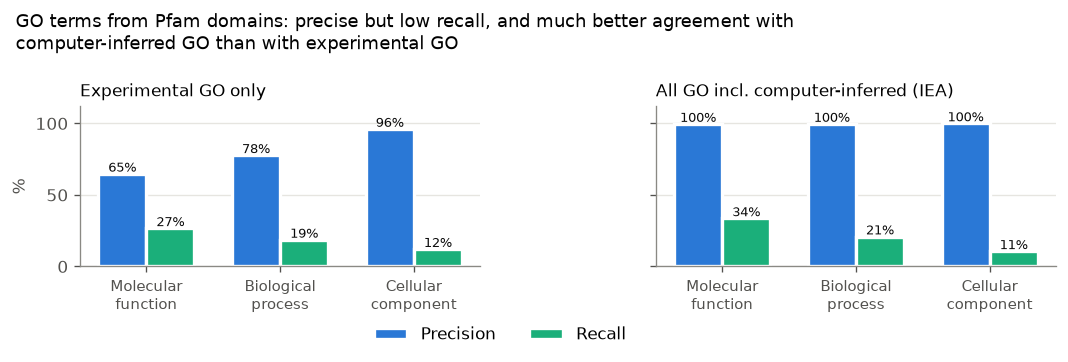

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, truth_name in zip(axes, truth_sets):
    rows = {ASPECTS[a]: step4_metrics[f"{truth_name}_{a}"] for a in ASPECTS}
    width = 0.36
    for offset, (measure, label, color) in zip((-width / 2, width / 2),
                                               [("precision_pct", "Precision", "#2a78d6"), ("recall_pct", "Recall", "#1baf7a")]):
        values = [r[measure] or 0 for r in rows.values()]
        bars = ax.bar([i + offset for i in range(len(rows))], values, width=width, color=color, label=label,
                      edgecolor="white", linewidth=2)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.0f}%", ha="center", color="#0b0b0b", fontsize=8)
    ax.set_xticks(range(len(rows)))
    ax.set_xticklabels([name.replace(" ", "\n") for name in rows], fontsize=9)
    ax.set_ylim(0, 112)
    ax.grid(axis="x", visible=False)
    ax.set_title(TRUTH_LABELS[truth_name], loc="left", fontsize=10)
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(1.05, -0.28), ncol=2)
fig.suptitle("GO terms from Pfam domains: precise but low recall, and much better agreement with\n"
             "computer-inferred GO than with experimental GO", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step4_go_scores.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "step4_go_scores.svg", bbox_inches="tight")
plt.show()

In [142]:
# How much of the precision comes from "correct but general" terms? Compare exact-term and hierarchy-aware scores.
pd.DataFrame({
    TRUTH_LABELS[name]: {
        "precision, exact terms": step4_metrics[name + "_exact_terms"]["precision_pct"],
        "precision, with hierarchy": step4_metrics[name]["precision_pct"],
        "recall, exact terms": step4_metrics[name + "_exact_terms"]["recall_pct"],
        "recall, with hierarchy": step4_metrics[name]["recall_pct"],
    } for name in truth_sets
})

,Experimental GO only,All GO incl. computer-inferred (IEA)
"precision, exact terms",25.55,97.21
"precision, with hierarchy",63.09,99.45
"recall, exact terms",8.22,18.25
"recall, with hierarchy",20.07,23.33


## Step 5: Final annotation table compared with RefSeq

The final table (`AnnotationCombiner`) gives every gene one name, from one of three sources:

| `product_source` | Name |
|---|---|
| `homology` | The Swiss-Prot name (status `confident` or `uncharacterized_match`) |
| `pfam_domain` | "*X* domain-containing protein", from the strongest Pfam domain, when homology gave no usable name |
| `none` | "hypothetical protein" |

Step 2 judged the homology names alone. Step 5 asks: **after adding the domain-based names, how much of the known biology does the final table capture?**

| Category | Meaning |
|---|---|
| Correct name | Homology name confirmed (same gene symbol or similar name, as in step 2) |
| Different name (review) | Homology name that doesn't match RefSeq automatically |
| Domain name, function known | Named from a domain; RefSeq knows the full function. Partial information |
| Domain name, function unknown | Named from a domain; RefSeq doesn't know the function either |
| Function missed | "hypothetical", "uncharacterized" or a DUF (domain of unknown function) name, but RefSeq knows the function |
| Function claimed, unknown | Functional homology name; RefSeq says unknown |
| Correctly unknown | Both say unknown |

Domain-based names are partial by design ("ABC transporter domain-containing protein" doesn't say which substrate), so they can't be scored as right or wrong by text matching. Instead we check whether the domain is **confirmed by UniProt's own Pfam annotation** for that protein, and sample some for manual review.

In [143]:
ANNOTATION_DIR = ROOT / "Structural_annotation/annotation_results"

FINAL_CATEGORIES = {
    "correct":              ("Correct name",                  "#2a78d6"),
    "different_name":       ("Different name (review)",       "#eda100"),
    "domain_known":         ("Domain name, function known",   "#6250d6"),
    "domain_unknown":       ("Domain name, function unknown", "#e87ba4"),
    "under_annotated":      ("Function missed",               "#eb6834"),
    "over_annotated":       ("Function claimed, unknown",     "#e34948"),
    "correctly_unknown":    ("Correctly unknown",             "#1baf7a"),
}

# UniProt's Pfam families per protein, without version numbers
uniprot_pfam = pd.read_csv(UNIPROT_PFAM, sep="\t", keep_default_na=False)
uniprot_pfam_sets = {
    row["Entry"]: {p for p in row["Pfam"].strip(";").split(";") if p}
    for _, row in uniprot_pfam.iterrows()
}
print(f"UniProt Pfam annotations for {len(uniprot_pfam_sets)} proteins")

UniProt Pfam annotations for 4403 proteins


In [144]:
def evaluate_final(database):
    """One row per matched gene: the final name, where it came from, and its category."""
    final = pd.read_csv(ANNOTATION_DIR / f"ecoli_{database}_annotation.tsv", sep="\t", keep_default_na=False)
    step2 = homology[database][["protein", "category"]].rename(columns={"category": "step2_category"})
    table = (gene_matches
             .merge(final[["protein", "product", "product_source", "homology_status", "pfam_accessions"]],
                    on="protein", how="left")
             .merge(step2, on="protein", how="left"))

    truth_known = ~table["refseq_product"].str.contains(UNKNOWN_FUNCTION)
    source = table["product_source"]
    named_by_homology = (source == "homology") & (table["homology_status"] == "confident")

    # "DUF123 domain-containing protein" names a domain of unknown function: no functional information
    domain_named = (source == "pfam_domain") & ~table["product"].str.startswith("DUF")

    table["category"] = "correctly_unknown"
    table.loc[~named_by_homology & truth_known, "category"] = "under_annotated"
    table.loc[domain_named & truth_known, "category"] = "domain_known"
    table.loc[domain_named & ~truth_known, "category"] = "domain_unknown"
    # Functional homology names keep their step 2 judgement
    step2_to_final = {"correct_same_gene": "correct", "correct_similar_name": "correct",
                      "different_name": "different_name", "over_annotated": "over_annotated"}
    table.loc[named_by_homology, "category"] = table.loc[named_by_homology, "step2_category"].map(step2_to_final)

    # Is at least one of our Pfam families also in UniProt's Pfam list for this protein?
    ours = table["pfam_accessions"].str.split(";").apply(lambda ids: {i.split(".")[0] for i in ids if i})
    theirs = table["uniprot"].map(uniprot_pfam_sets)
    table["uniprot_has_pfam"] = theirs.notna()
    table["domain_confirmed"] = [bool(o & t) if isinstance(t, set) else False for o, t in zip(ours, theirs)]
    return table


final = {db: evaluate_final(db) for db in DATABASES}

/var/folders/6g/mc7s95_n393463z88d1hz47c0000gn/T/ipykernel_18114/2666117241.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  truth_known = ~table["refseq_product"].str.contains(UNKNOWN_FUNCTION)
/var/folders/6g/mc7s95_n393463z88d1hz47c0000gn/T/ipykernel_18114/2666117241.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  truth_known = ~table["refseq_product"].str.contains(UNKNOWN_FUNCTION)


### Metrics

Measured over genes whose function RefSeq knows:

- **correct_name_pct**: share with a correct full name
- **any_functional_info_pct**: share with any functional information (correct name, different name, or a domain-based name)
- **hypothetical_pct**: share left as "hypothetical"/"uncharacterized" although the function is known

Plus **domain_names_confirmed_pct**: of the domain-based names, the share whose Pfam family UniProt also lists for that protein.

In [145]:
def final_metrics(table):
    counts = table["category"].value_counts().reindex(list(FINAL_CATEGORIES)).fillna(0).astype(int)
    known = counts[["correct", "different_name", "domain_known", "under_annotated"]].sum()
    domain_named = table[table["product_source"] == "pfam_domain"]
    checkable = domain_named[domain_named["uniprot_has_pfam"]]
    return {
        "genes_evaluated": len(table),
        "genes_with_known_function": int(known),
        **{name: int(value) for name, value in counts.items()},
        "correct_name_pct": round(float(100 * counts["correct"] / known), 2),
        "any_functional_info_pct": round(float(100 * counts[["correct", "different_name", "domain_known"]].sum() / known), 2),
        "hypothetical_pct": round(float(100 * counts["under_annotated"] / known), 2),
        "domain_names": len(domain_named),
        "domain_names_confirmed_pct": round(float(100 * checkable["domain_confirmed"].mean()), 2) if len(checkable) else None,
    }


step5_metrics = {db: final_metrics(table) for db, table in final.items()}
(OUT_DIR / "step5_final_metrics.json").write_text(json.dumps(step5_metrics, indent=2))
pd.DataFrame(step5_metrics).rename(columns=DATABASES)

,Full Swiss-Prot,Swiss-Prot without E. coli relatives
genes_evaluated,4118.00,4118.00
genes_with_known_function,3766.00,3766.00
correct,3335.00,2060.00
different_name,80.00,318.00
domain_known,282.00,1273.00
domain_unknown,117.00,134.00
under_annotated,69.00,115.00
over_annotated,21.00,9.00
correctly_unknown,214.00,209.00
correct_name_pct,88.56,54.70


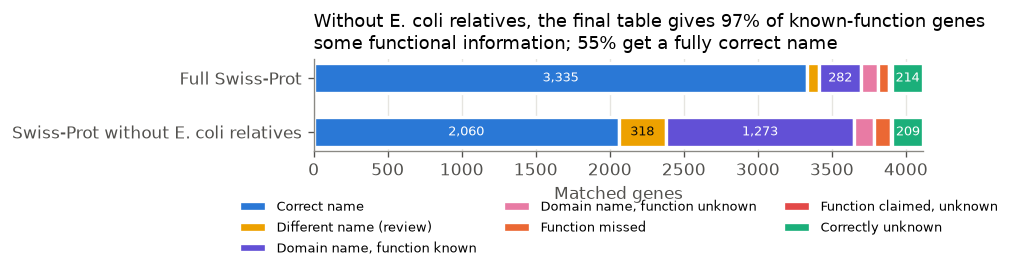

In [146]:
fig, ax = plt.subplots(figsize=(8, 3))
labels = [DATABASES[db] for db in DATABASES][::-1]
left = pd.Series(0, index=labels, dtype=float)
for key, (label, color) in FINAL_CATEGORIES.items():
    values = pd.Series([step5_metrics[db][key] for db in DATABASES][::-1], index=labels)
    ax.barh(labels, values, left=left, color=color, label=label, height=0.55,
            edgecolor="white", linewidth=2)
    text_color = "#0b0b0b" if key in ("different_name", "domain_unknown") else "white"
    for y, (value, start) in enumerate(zip(values, left)):
        if value >= 150:
            ax.text(start + value / 2, y, f"{value:,}", ha="center", va="center", color=text_color, fontsize=8)
    left += values
ax.set_xlabel("Matched genes")
ax.set_xlim(0, left.max())
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.4), frameon=False, fontsize=8)
novel = step5_metrics["swissprot_no_ecoli"]
ax.set_title(f"Without E. coli relatives, the final table gives {novel['any_functional_info_pct']:.0f}% of known-function genes\n"
             f"some functional information; {novel['correct_name_pct']:.0f}% get a fully correct name", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step5_final_categories.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "step5_final_categories.svg", bbox_inches="tight")
plt.show()

### What the domain step adds on top of homology

For genes whose function RefSeq knows: the share with any functional information from homology alone (step 2) vs. the final table (step 5).

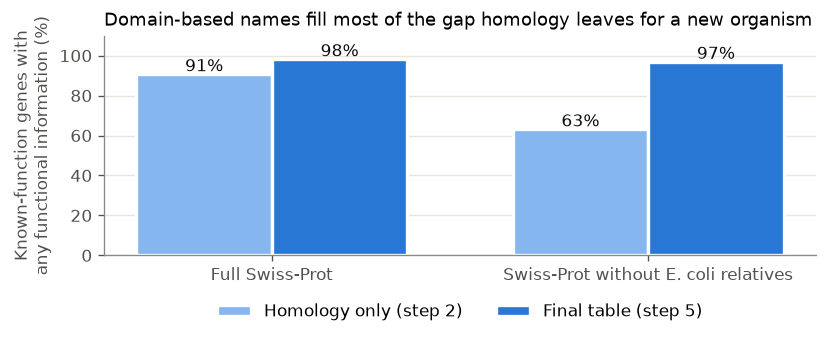

,Homology only (step 2),Final table (step 5)
Full Swiss-Prot,90.7,98.2
Swiss-Prot without E. coli relatives,63.1,96.9


In [147]:
def informative_share(categories, informative):
    known = categories.isin(informative + ["under_annotated"])
    return 100 * categories[known].isin(informative).mean()


comparison = pd.DataFrame({
    "Homology only (step 2)": {
        DATABASES[db]: informative_share(homology[db]["category"], ["correct_same_gene", "correct_similar_name", "different_name"])
        for db in DATABASES
    },
    "Final table (step 5)": {
        DATABASES[db]: informative_share(final[db]["category"], ["correct", "different_name", "domain_known"])
        for db in DATABASES
    },
}).round(1)

fig, ax = plt.subplots(figsize=(7, 3))
x = range(len(comparison))
width = 0.36
for offset, (column, color) in zip((-width / 2, width / 2), zip(comparison.columns, ("#86b6ef", "#2a78d6"))):
    bars = ax.bar([i + offset for i in x], comparison[column], width=width, color=color, label=column,
                  edgecolor="white", linewidth=2)
    for bar, value in zip(bars, comparison[column]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.0f}%", ha="center", color="#0b0b0b")
ax.set_xticks(list(x))
ax.set_xticklabels(comparison.index)
ax.set_ylim(0, 110)
ax.set_ylabel("Known-function genes with\nany functional information (%)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.set_title("Domain-based names fill most of the gap homology leaves for a new organism", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "step5_homology_vs_final.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "step5_homology_vs_final.svg", bbox_inches="tight")
plt.show()
comparison

### Examples and manual review of domain-based names

In [148]:
FINAL_COLUMNS = ["protein", "gene", "refseq_product", "product", "product_source", "homology_status",
                 "domain_confirmed", "category"]

for category in ["domain_known", "domain_unknown", "under_annotated"]:
    for db, table in final.items():
        rows = table.loc[table["category"] == category, FINAL_COLUMNS]
        print(f"\n=== {DATABASES[db]}: {FINAL_CATEGORIES[category][0]} ({len(rows)}) ===")
        display(rows.sample(min(8, len(rows)), random_state=1))


=== Full Swiss-Prot: Domain name, function known (282) ===


,protein,gene,refseq_product,product,product_source,homology_status,domain_confirmed,category
1407,NC_000913.3_1475,ydeN,putative sulfatase YdeN,Sulfatase domain-containing protein,pfam_domain,uncharacterized_match,True,domain_known
3763,NC_000913.3_3939,yjbF,lipoprotein YjbF,"Group 4 capsule polysaccharide lipoprotein gfcB, YjbF domain-containing protein",pfam_domain,uncharacterized_match,True,domain_known
879,NC_000913.3_920,ycbF,putative fimbrial chaperone YcbF,"Pili and flagellar-assembly chaperone, PapD N-terminal domain-containing pro...",pfam_domain,uncharacterized_match,True,domain_known
1440,NC_000913.3_1510,ydeE,dipeptide exporter,Major Facilitator Superfamily domain-containing protein,pfam_domain,uncharacterized_match,True,domain_known
3753,NC_000913.3_3929,arpA,ankyrin-like regulator,"ShET2 enterotoxin, N-terminal region domain-containing protein",pfam_domain,weak_match,True,domain_known
3302,NC_000913.3_3458,yhjJ,peptidase M16 family protein YhjJ,Peptidase M16 inactive domain-containing protein,pfam_domain,uncharacterized_match,True,domain_known
1326,NC_000913.3_1386,ynbC,hydrolase/methyltransferase domain-containing protein YnbC,Putative methyltransferase domain-containing protein,pfam_domain,uncharacterized_match,True,domain_known
1823,NC_000913.3_1906,yedL,putative acetyltransferase YedL,Acetyltransferase (GNAT) family domain-containing protein,pfam_domain,uncharacterized_match,True,domain_known



=== Swiss-Prot without E. coli relatives: Domain name, function known (1273) ===


,protein,gene,refseq_product,product,product_source,homology_status,domain_confirmed,category
673,NC_000913.3_714,mngA,2-O-alpha-mannosyl-D-glycerate specific PTS enzyme II,"Phosphoenolpyruvate-dependent sugar phosphotransferase system, EIIA 2 domain...",pfam_domain,weak_match,True,domain_known
851,NC_000913.3_892,ycaQ,interstrand DNA crosslink repair glycosylase,DNA glycosylase AlkZ-like domain-containing protein,pfam_domain,no_match,True,domain_known
4030,NC_000913.3_4227,fimB,Type 1 fimbriae regulatory protein FimB,Phage integrase family domain-containing protein,pfam_domain,weak_match,True,domain_known
3494,NC_000913.3_3655,bglH,cryptic carbohydrate-specific outer membrane porin,LamB porin domain-containing protein,pfam_domain,weak_match,True,domain_known
4117,NC_000913.3_4319,yjtD,putative tRNA/rRNA methyltransferase YjtD,SpoU rRNA Methylase family domain-containing protein,pfam_domain,uncharacterized_match,True,domain_known
2031,NC_000913.3_2133,psuK,putative pseudouridine kinase,pfkB family carbohydrate kinase domain-containing protein,pfam_domain,weak_match,True,domain_known
2776,NC_000913.3_2912,yghD,putative type II secretion system M-type protein YghD,"Type II secretion system (T2SS), protein M domain-containing protein",pfam_domain,weak_match,True,domain_known
1735,NC_000913.3_1816,yebZ,CopD family protein,"Copper resistance protein D-like, N-terminal domain-containing protein",pfam_domain,weak_match,True,domain_known



=== Full Swiss-Prot: Domain name, function unknown (117) ===


...

,protein,gene,refseq_product,product,product_source,homology_status,domain_confirmed,category
1194,NC_000913.3_1249,ymiA,uncharacterized protein YmiA,Protein YmiA-like domain-containing protein,pfam_domain,no_match,True,domain_unknown
1094,NC_000913.3_1143,ymgG,PF13436 family protein YmgG,YMGG-like Gly-zipper domain-containing protein,pfam_domain,weak_match,True,domain_unknown
2557,NC_000913.3_2683,ygbA,protein YgbA,Nitrous oxide-stimulated promoter domain-containing protein,pfam_domain,no_match,True,domain_unknown
256,NC_000913.3_273,yagK,uncharacterized protein YagK,YagK/YfjJ C-terminal domain-containing protein,pfam_domain,no_match,True,domain_unknown
1721,NC_000913.3_1802,yobH,uncharacterized protein YobH,YobH-like protein domain-containing protein,pfam_domain,uncharacterized_match,True,domain_unknown
3261,NC_000913.3_3411,yhhH,PF15631 family protein YhhH,NTF2 fold immunity protein domain-containing protein,pfam_domain,no_match,True,domain_unknown
1568,NC_000913.3_1646,ydhT,uncharacterized protein YdhT,YdhT N-terminal domain-containing protein,pfam_domain,no_match,True,domain_unknown
535,NC_000913.3_568,ybdF,PF04237 family protein YbdF,YjbR domain-containing protein,pfam_domain,no_match,True,domain_unknown



=== Full Swiss-Prot: Function missed (69) ===


,protein,gene,refseq_product,product,product_source,homology_status,domain_confirmed,category
3646,NC_000913.3_3817,yiiG,DUF3829 domain-containing lipoprotein YiiG,Uncharacterized protein YiiG,homology,uncharacterized_match,True,under_annotated
2090,NC_000913.3_2193,yfaQ,tandem DUF2300 domain-containing protein YfaQ,Uncharacterized protein YfaQ,homology,uncharacterized_match,True,under_annotated
1707,NC_000913.3_1788,yoaH,UFP0181 family protein YoaH,UPF0181 protein YoaH,homology,uncharacterized_match,True,under_annotated
2356,NC_000913.3_2471,yfgG,Ni/Co stress response protein YfgG,Uncharacterized protein YfgG,homology,uncharacterized_match,True,under_annotated
3880,NC_000913.3_4062,yjeI,DUF4156 domain-containing lipoprotein YjeI,Uncharacterized protein YjeI,homology,uncharacterized_match,True,under_annotated
2740,NC_000913.3_2876,yggC,P-loop NTPase domain-containing protein YggC,Uncharacterized protein YggC,homology,uncharacterized_match,False,under_annotated
2283,NC_000913.3_2396,yfeY,DUF1131 domain-containing lipoprotein YfeY,Uncharacterized protein YfeY,homology,uncharacterized_match,True,under_annotated
3183,NC_000913.3_3331,yhgE,putative transport protein YhgE,Uncharacterized protein YhgE,homology,uncharacterized_match,True,under_annotated



=== Swiss-Prot without E. coli relatives: Function missed (115) ===


,protein,gene,refseq_product,product,product_source,homology_status,domain_confirmed,category
3371,NC_000913.3_3530,yibG,tetratricopeptide-like domain-containing protein YibG,hypothetical protein,none,no_match,False,under_annotated
1707,NC_000913.3_1788,yoaH,UFP0181 family protein YoaH,UPF0181 protein CKO_01169,homology,uncharacterized_match,True,under_annotated
2233,NC_000913.3_2345,ypdI,colanic acid synthesis putative lipoprotein YpdI,hypothetical protein,none,no_match,False,under_annotated
3006,NC_000913.3_3147,gltF,periplasmic protein GltF,DUF1120 domain-containing protein,pfam_domain,no_match,True,under_annotated
2653,NC_000913.3_2780,ygdT,YgdT,hypothetical protein,none,no_match,False,under_annotated
3804,NC_000913.3_3984,yjcH,DUF485 domain-containing inner membrane protein YjcH,DUF485 domain-containing protein,pfam_domain,no_match,True,under_annotated
2792,NC_000913.3_2928,yghR,putative ATP-binding protein YghR,hypothetical protein,none,no_match,False,under_annotated
2284,NC_000913.3_2397,yfeZ,putative inner membrane protein,DUF2919 domain-containing protein,pfam_domain,no_match,True,under_annotated


In [149]:
# 25 random domain-based names (function known in RefSeq) from the "new organism" run, for checking by hand.
# Fill consistent with: yes (domain fits the real function) / partly / no. Never overwritten once it exists.
domain_review = (final["swissprot_no_ecoli"]
                 .loc[lambda t: t["category"] == "domain_known", FINAL_COLUMNS]
                 .sample(25, random_state=7))
domain_review["consistent"] = ""
domain_review_file = OUT_DIR / "step5_domain_name_review.tsv"
if domain_review_file.exists():
    print(f"{domain_review_file.name} already exists; not overwriting your manual answers")
else:
    domain_review.to_csv(domain_review_file, sep="\t", index=False)
    print(f"Wrote {len(domain_review)} rows to {domain_review_file} for manual review")

step5_domain_name_review.tsv already exists; not overwriting your manual answers


In [150]:
# Run after filling in step5_domain_name_review.tsv
answers = pd.read_csv(domain_review_file, sep="\t", keep_default_na=False)
filled = answers[answers["consistent"].str.strip() != ""]
if filled.empty:
    print("No answers yet: fill the consistent column in", domain_review_file.name)
else:
    display(filled["consistent"].value_counts(normalize=True).mul(100).round(1).rename("% of reviewed"))

No answers yet: fill the consistent column in step5_domain_name_review.tsv
